# 01 · Retrieval Quality Comparison (H1)

**VL-JEPA vs CLIP** — Recall@K, nDCG@10, MRR, mAP per dataset.

Feed your data by editing `findings_data/retrieval_metrics.csv`
(or run `scripts/compare_models.py`, which this loader also picks up
from `results/metrics/comparison_table.csv`). Example data is shown
until real numbers are available.

In [1]:
import research_utils as ru

df = ru.load_findings(
    "retrieval_metrics",
    fallbacks=[ru.PIPELINE_RESULTS_DIR / "metrics" / "comparison_table.csv"],
)
df

,model,dataset,recall@1,recall@5,recall@10,ndcg@10,mrr,map,num_queries
0,vljepa,ucf_crime,0.412,0.648,0.754,0.528,0.503,0.461,40
1,vljepa,rlvs,0.465,0.701,0.793,0.571,0.554,0.502,30
2,clip,ucf_crime,0.372,0.598,0.706,0.481,0.459,0.415,40
3,clip,rlvs,0.421,0.655,0.752,0.522,0.501,0.448,30


## Full metrics table

Best value per metric column is highlighted in green.

In [2]:
ru.style_table(df)

,model,dataset,recall@1,recall@5,recall@10,ndcg@10,mrr,map,num_queries
0,vljepa,ucf_crime,0.412,0.648,0.754,0.528,0.503,0.461,40
1,vljepa,rlvs,0.465,0.701,0.793,0.571,0.554,0.502,30
2,clip,ucf_crime,0.372,0.598,0.706,0.481,0.459,0.415,40
3,clip,rlvs,0.421,0.655,0.752,0.522,0.501,0.448,30


## Recall@K by dataset

[research] figure -> h1_recall_panels.png, h1_recall_panels.pdf


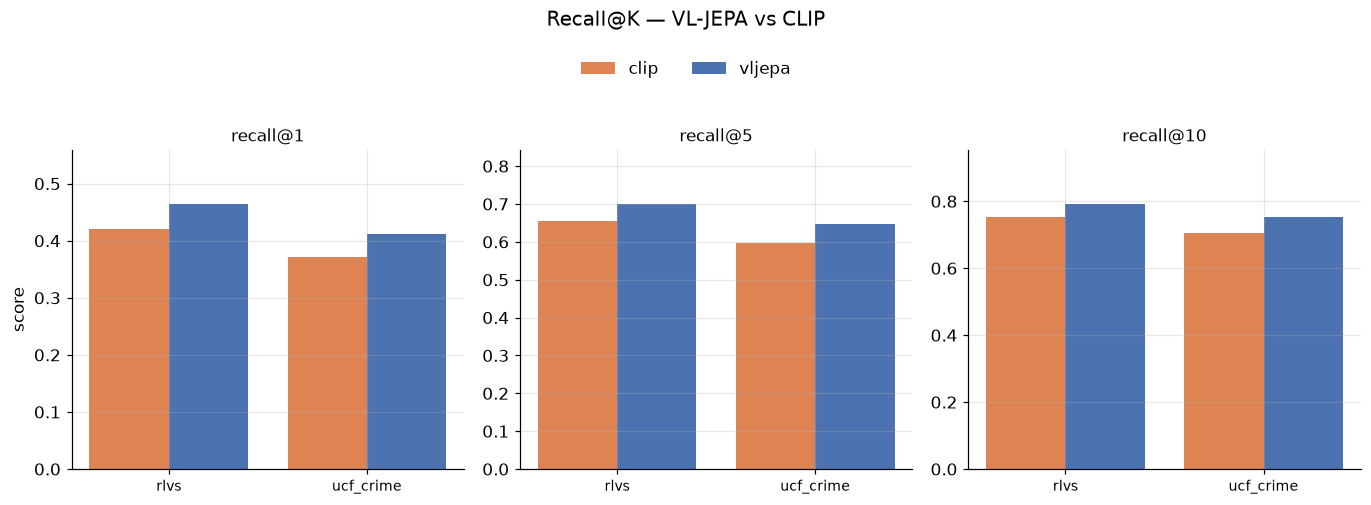

In [3]:
fig, axes = ru.plot_metric_panels(
    df, metrics=["recall@1", "recall@5", "recall@10"],
    group="dataset", hue="model", suptitle="Recall@K — VL-JEPA vs CLIP",
    save="h1_recall_panels",
)

[research] figure -> h1_recall_curves.png, h1_recall_curves.pdf


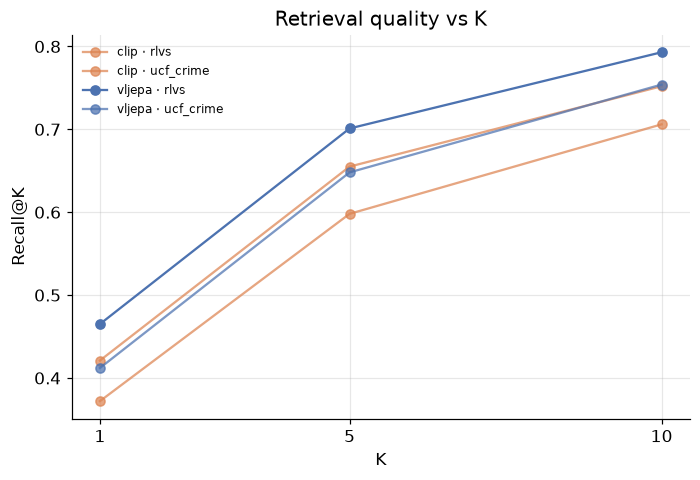

In [4]:
fig, ax = ru.plot_recall_curves(df, ks=(1, 5, 10), hue="model", group="dataset",
                               save="h1_recall_curves")

## Ranking-oriented metrics

nDCG@10, MRR and mAP reward putting the first relevant clip at rank 1.

[research] figure -> h1_ranking_panels.png, h1_ranking_panels.pdf


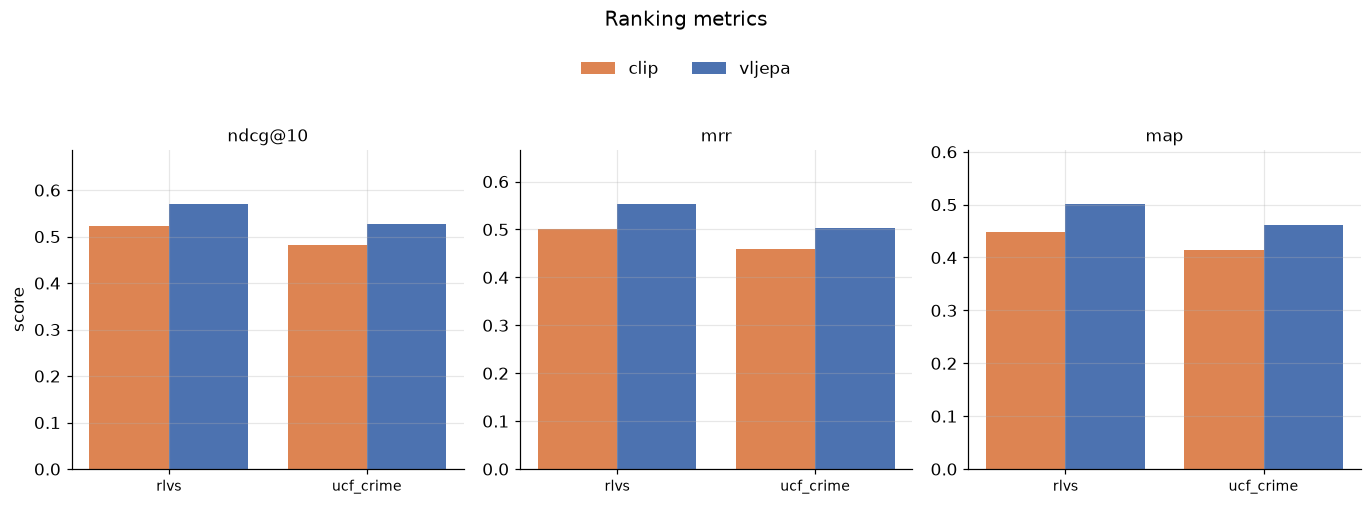

In [5]:
fig, axes = ru.plot_metric_panels(
    df, metrics=["ndcg@10", "mrr", "map"],
    group="dataset", hue="model", suptitle="Ranking metrics",
    save="h1_ranking_panels",
)

## Head-to-head delta

Relative improvement (%) of VL-JEPA over CLIP — per dataset and overall. Positive bars support **H1**.

[research] figure -> h1_delta_by_dataset.png, h1_delta_by_dataset.pdf


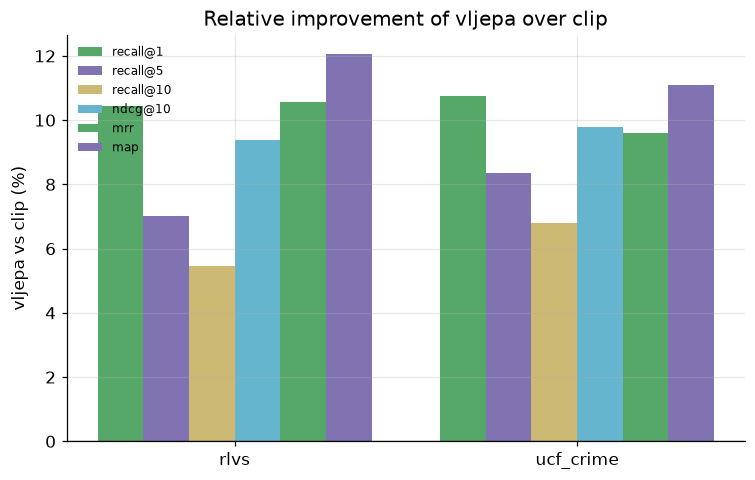

In [6]:
fig, ax = ru.plot_metric_delta(df, model_a="vljepa", model_b="clip",
                              group="dataset", save="h1_delta_by_dataset")

[research] figure -> h1_delta_overall.png, h1_delta_overall.pdf


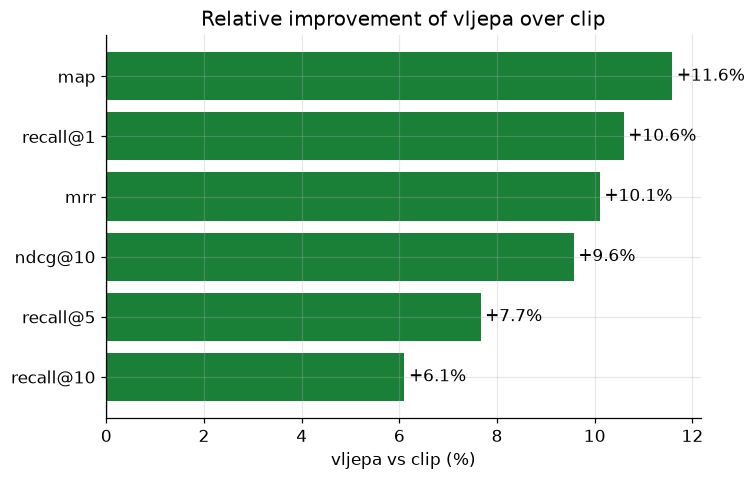

In [7]:
fig, ax = ru.plot_metric_delta(df, model_a="vljepa", model_b="clip",
                              save="h1_delta_overall")

## Export

LaTeX + CSV copies for the report land in `research/outputs/`.

In [8]:
ru.export_table(df, "h1_retrieval_metrics")

delta = (df.pivot_table(index="dataset", columns="model", values=["recall@1", "recall@5", "recall@10", "ndcg@10", "mrr", "map"], aggfunc="mean")
        .round(3))
ru.export_table(delta, "h1_model_by_dataset_pivot")

[research] table -> h1_retrieval_metrics.csv, h1_retrieval_metrics.tex
[research] table -> h1_model_by_dataset_pivot.csv, h1_model_by_dataset_pivot.tex


[WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/h1_model_by_dataset_pivot.csv'),
 WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/h1_model_by_dataset_pivot.tex')]